# ДЗ4. Сегментация изображений

1. Настроить параметры алгоритма разрастания областей так, чтобы был выделен весь газон.
2. Реализовать собственный критерий однородности, отличный от предложенного. Провести сравнение.
3. Повторить принцип реализации watershed + distance transform для подсчёта количества пальм.

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

---
## Пункт 1. Разрастание областей (region growing) на sar_1.jpg

(300, 400)


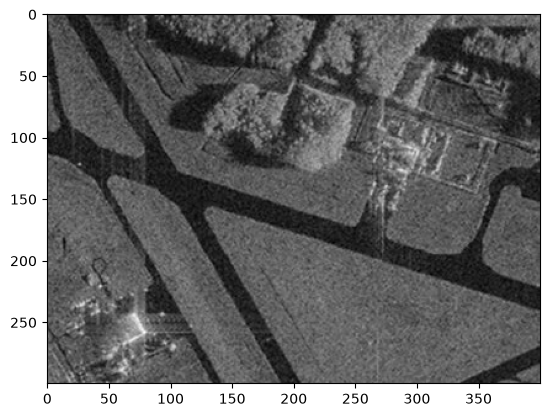

In [2]:
image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
print(image_gray.shape)
plt.imshow(image_gray, cmap="gray")

In [3]:
def region_growing(image, seed_point, homo_fun, r, T):
    img = image.astype(np.float64)
    mask = np.zeros(image.shape, np.uint8)
    mask[seed_point] = 1
    kernel = np.ones((2*r + 1, 2*r + 1), np.uint8)
    it = 0
    while True:
        frontier = (cv2.dilate(mask, kernel) > 0) & (mask == 0)
        if not frontier.any():
            break
        new = frontier & homo_fun(img, mask, r, T)
        if not new.any():
            break
        mask[new] = 1
        it += 1
    print('итераций:', it, ' площадь:', np.count_nonzero(mask))
    return mask * 255

In [4]:
def homo_average(img, mask, r, T):
    av_val = img[mask > 0].mean()
    return np.abs(img - av_val) <= T

### Подбор параметров

итераций: 149  площадь: 21596


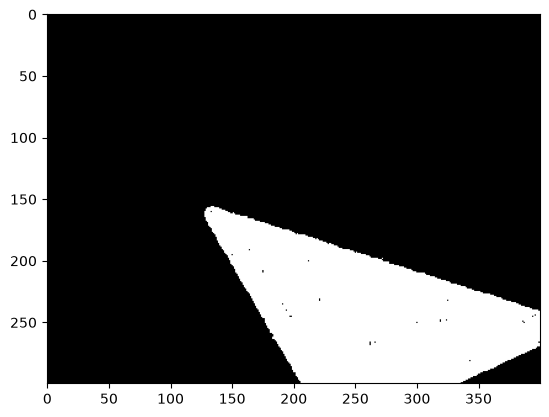

In [5]:
seed_point = (250, 250)
r = 1
T = 30

mask_avg = region_growing(image_gray, seed_point, homo_average, r, T)
plt.imshow(mask_avg, cmap="gray")

In [6]:
for T_try in (10, 20, 30, 33, 34):
    mask_try = region_growing(image_gray, seed_point, homo_average, r, T_try)
    print('T=%2d  площадь=%6d' % (T_try, np.count_nonzero(mask_try)))

итераций: 152  площадь: 16072
T=10  площадь= 16072
итераций: 149  площадь: 20914
T=20  площадь= 20914
итераций: 149  площадь: 21596
T=30  площадь= 21596
итераций: 149  площадь: 21674
T=33  площадь= 21674
итераций: 410  площадь: 62485
T=34  площадь= 62485


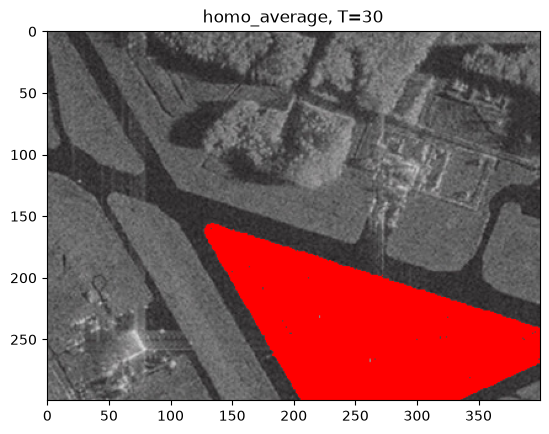

In [7]:
def show_overlay(image, mask, title=''):
    overlay = image.copy()
    overlay[mask > 0] = (0, 0, 255)
    plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
    plt.title(title)

show_overlay(image, mask_avg, 'homo_average, T=%s' % T)

---
## Пункт 2. Собственный критерий однородности

In [8]:
def homo_local(img, mask, r, T):
    m = (mask > 0).astype(np.float64)
    k = np.ones((2*r + 1, 2*r + 1), np.float64)
    s = cv2.filter2D(img * m, -1, k)
    n = cv2.filter2D(m, -1, k)
    local_av = s / np.maximum(n, 1)
    return (n > 0) & (np.abs(img - local_av) <= T)

итераций: 27  площадь: 16287


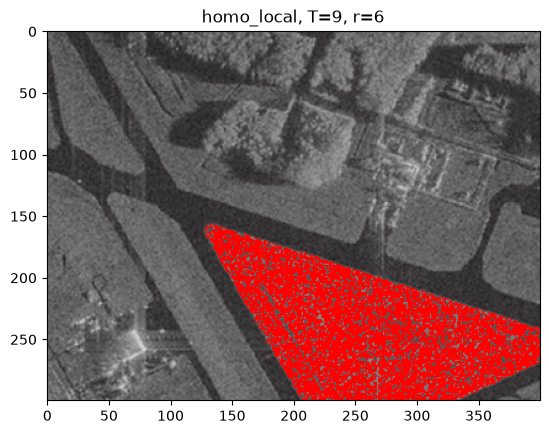

In [9]:
T2 = 9
r2 = 6

mask_local = region_growing(image_gray, seed_point, homo_local, r2, T2)
show_overlay(image, mask_local, 'homo_local, T=%s, r=%s' % (T2, r2))

### Сравнение критериев

homo_average:        21596 пикселей
homo_local:          16287 пикселей
homo_local + CLOSE:  21217 пикселей


Text(0.5, 1.0, 'homo_local + CLOSE')

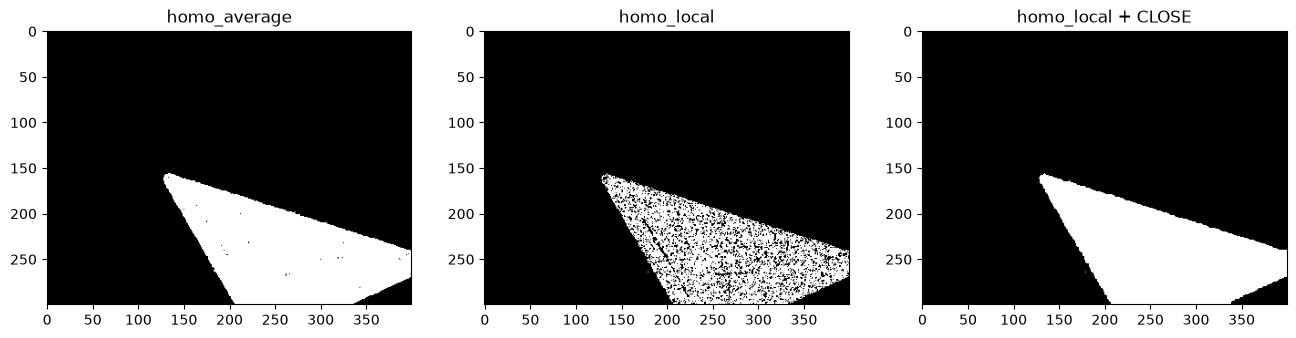

In [10]:
mask_local_clean = cv2.morphologyEx(mask_local, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))

print('homo_average:       ', np.count_nonzero(mask_avg),         'пикселей')
print('homo_local:         ', np.count_nonzero(mask_local),       'пикселей')
print('homo_local + CLOSE: ', np.count_nonzero(mask_local_clean), 'пикселей')

plt.figure(figsize=(16, 5))
plt.subplot(1, 3, 1); plt.imshow(mask_avg,         cmap="gray"); plt.title('homo_average')
plt.subplot(1, 3, 2); plt.imshow(mask_local,       cmap="gray"); plt.title('homo_local')
plt.subplot(1, 3, 3); plt.imshow(mask_local_clean, cmap="gray"); plt.title('homo_local + CLOSE')

---
## Пункт 3. Подсчёт пальм: watershed + distance transform

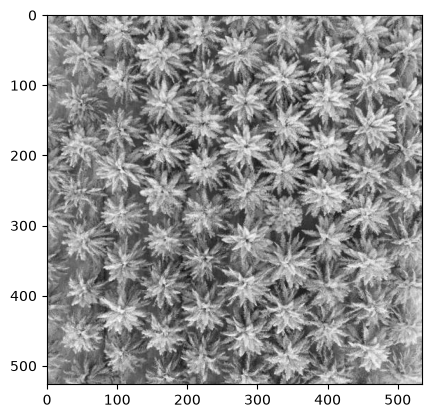

In [11]:
palm = cv2.imread('palm_1.JPG')
palm_gray = cv2.cvtColor(palm, cv2.COLOR_BGR2GRAY)
plt.imshow(palm_gray, cmap="gray")

порог Оцу: 158.0


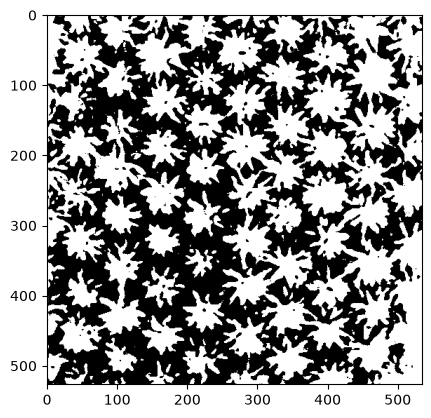

In [12]:
blur = cv2.medianBlur(palm_gray, 5)
otsu_T, thresh = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print('порог Оцу:', otsu_T)
plt.imshow(thresh, cmap="gray")

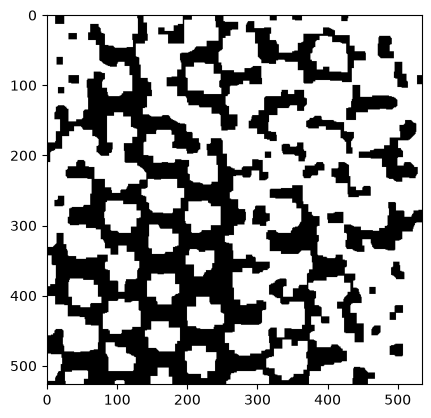

In [13]:
kernel = np.ones((5, 5), np.uint8)
thresh = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel, iterations=2)
thresh = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=2)
plt.imshow(thresh, cmap="gray")

max расстояние: 53.953487


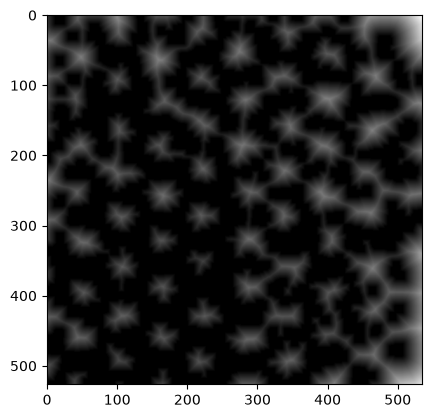

In [14]:
dist = cv2.distanceTransform(thresh, cv2.DIST_L2, 5)
print('max расстояние:', dist.max())
plt.imshow(dist, cmap="gray")

### Вариант 1. Глобальный порог по distance transform

найдено пальм: 77


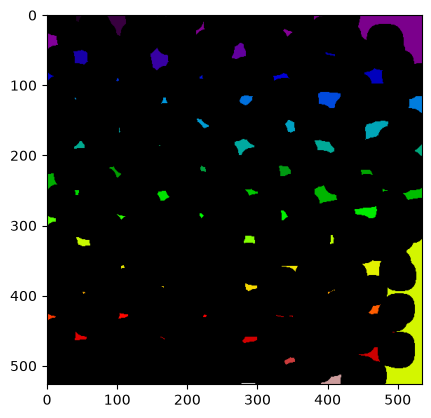

In [15]:
coef = 0.32

_, core_mask = cv2.threshold(dist, coef * dist.max(), 255, cv2.THRESH_BINARY)
core_mask = core_mask.astype(np.uint8)
n_found, markers = cv2.connectedComponents(core_mask)
print('найдено пальм:', n_found - 1)
plt.imshow(markers, cmap="nipy_spectral")

In [16]:
for coef_try in (0.2, 0.25, 0.3, 0.32, 0.4, 0.5):
    _, mask_try = cv2.threshold(dist, coef_try * dist.max(), 255, cv2.THRESH_BINARY)
    n_try, _ = cv2.connectedComponents(mask_try.astype(np.uint8))
    print('coef=%.2f  компонент=%3d' % (coef_try, n_try - 1))

coef=0.20  компонент= 67
coef=0.25  компонент= 70
coef=0.30  компонент= 73
coef=0.32  компонент= 77
coef=0.40  компонент= 30
coef=0.50  компонент=  8


### Вариант 2. Локальные максимумы distance transform

In [17]:
frac = 0.2

for size_try in (31, 41, 51, 61):
    k_try = np.ones((size_try, size_try), np.uint8)
    peaks_try = ((dist == cv2.dilate(dist, k_try)) & (dist > frac * dist.max())).astype(np.uint8)
    n_try, _ = cv2.connectedComponents(peaks_try)
    print('size=%2d  пикселей=%3d  компонент=%3d' % (size_try, int(peaks_try.sum()), n_try - 1))

size=31  пикселей=129  компонент= 93
size=41  пикселей=127  компонент= 91
size=51  пикселей=122  компонент= 86
size=61  пикселей=121  компонент= 85


In [18]:
size = 51

k = np.ones((size, size), np.uint8)
peaks = ((dist == cv2.dilate(dist, k)) & (dist > frac * dist.max())).astype(np.uint8)

seeds = cv2.dilate(peaks, np.ones((9, 9), np.uint8))
_, seed_labels, _, centers = cv2.connectedComponentsWithStats(seeds)
centers = centers[1:]

print('пикселей-вершин:    ', int(peaks.sum()))
print('вершин до утолщения:', cv2.connectedComponents(peaks)[0] - 1)
print('найдено пальм:      ', len(centers))

пикселей-вершин:     122
вершин до утолщения: 86
найдено пальм:       83


Text(0.5, 1.0, 'центров: 83 (size=51, frac=0.20)')

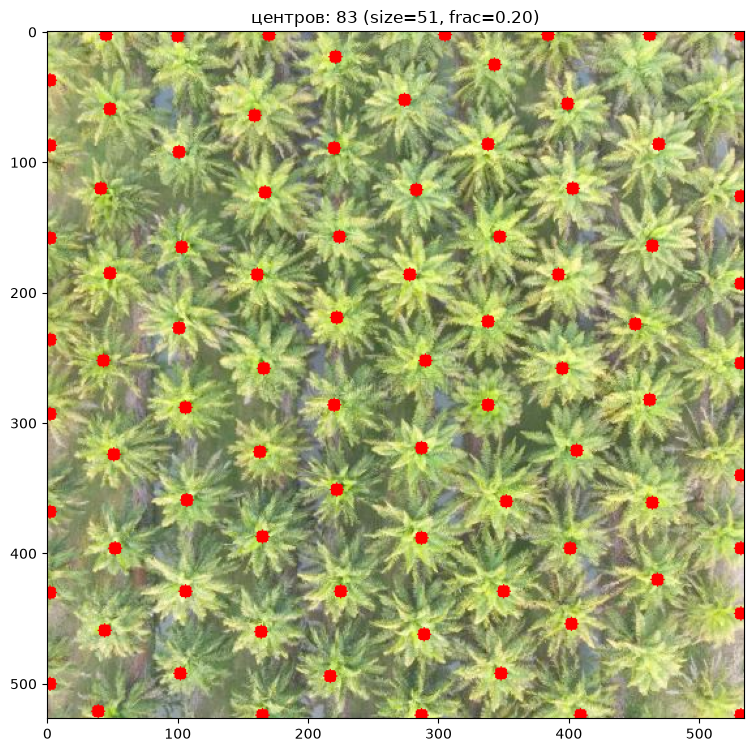

In [19]:
vis = palm.copy()
for (x, y) in centers:
    cv2.circle(vis, (int(x), int(y)), 5, (0, 0, 255), -1)

plt.figure(figsize=(9, 9))
plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
plt.title('центров: %d (size=%d, frac=%.2f)' % (len(centers), size, frac))

### Watershed по найденным центрам

маркеров до watershed:    83
областей после watershed: 83


Text(0.5, 1.0, 'границы крон')

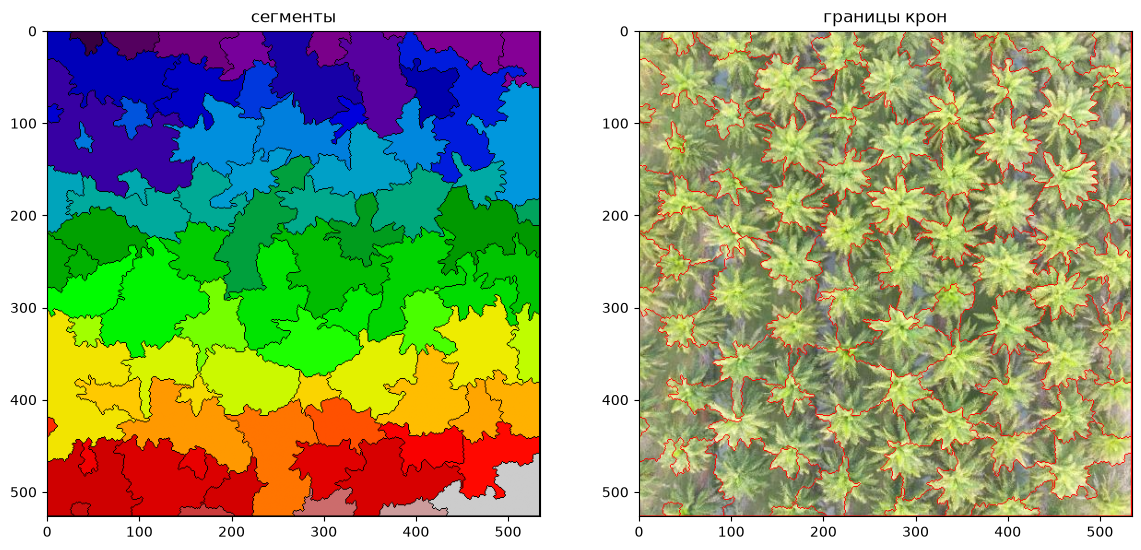

In [20]:
segments = cv2.watershed(palm, seed_labels.astype(np.int32).copy())

segment_ids = [v for v in np.unique(segments) if v > 0]
print('маркеров до watershed:   ', len(centers))
print('областей после watershed:', len(segment_ids))

result = palm.copy()
result[segments == -1] = (0, 0, 255)

plt.figure(figsize=(14, 7))
plt.subplot(1, 2, 1); plt.imshow(segments, cmap="nipy_spectral"); plt.title('сегменты')
plt.subplot(1, 2, 2); plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB)); plt.title('границы крон')